In [1]:
# Basic libraries
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# XGBoost
from xgboost import XGBClassifier

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully.")

TensorFlow version: 2.20.0
Libraries loaded successfully.


In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/dog.txt
/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/example_dna.fa
/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/human.txt
/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/chimpanzee.txt


In [3]:
human_path = "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/human.txt"
chimp_path = "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/chimpanzee.txt"
dog_path = "//kaggle/input/datasets/nageshsingh/dna-sequence-dataset/dog.txt"

human = pd.read_csv(human_path, sep="\t")
chimp = pd.read_csv(chimp_path, sep="\t")
dog = pd.read_csv(dog_path, sep="\t")

print("Human:", human.shape)
print("Chimpanzee:", chimp.shape)
print("Dog:", dog.shape)

Human: (4380, 2)
Chimpanzee: (1682, 2)
Dog: (820, 2)


In [4]:
print("Human columns:")
print(human.columns)

print("\nHuman sample:")
display(human.head())

print("\nChimpanzee sample:")
display(chimp.head())

print("\nDog sample:")
display(dog.head())

Human columns:
Index(['sequence', 'class'], dtype='object')

Human sample:


,sequence,class
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3



Chimpanzee sample:


,sequence,class
0,ATGCCCCAACTAAATACCGCCGTATGACCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTATTCGCTTCATTCGCTGCCCCCACAATCCTAG...,4
2,ATGGCCTCGCGCTGGTGGCGGTGGCGACGCGGCTGCTCCTGGAGGC...,4
3,ATGGCCTCGCGCTGGTGGCGGTGGCGACGCGGCTGCTCCTGGAGGC...,4
4,ATGGGCAGCGCCAGCCCGGGTCTGAGCAGCGTGTCCCCCAGCCACC...,6



Dog sample:


,sequence,class
0,ATGCCACAGCTAGATACATCCACCTGATTTATTATAATCTTTTCAA...,4
1,ATGAACGAAAATCTATTCGCTTCTTTCGCTGCCCCCTCAATAATAG...,4
2,ATGGAAACACCCTTCTACGGCGATGAGGCGCTGAGCGGCCTGGGCG...,6
3,ATGTGCACTAAAATGGAACAGCCCTTCTACCACGACGACTCATACG...,6
4,ATGAGCCGGCAGCTAAACAGAAGCCAGAACTGCTCCTTCAGTGACG...,0


In [5]:
human["species"] = "Human"
chimp["species"] = "Chimpanzee"
dog["species"] = "Dog"

data = pd.concat([human, chimp, dog], ignore_index=True)

print("Combined dataset shape:", data.shape)
display(data.head())

Combined dataset shape: (6882, 3)


,sequence,class,species
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4,Human
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4,Human
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Human
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Human
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3,Human


In [6]:
print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nClass distribution:")
print(data["class"].value_counts().sort_index())

print("\nSpecies distribution:")
print(data["species"].value_counts())

Missing values:
sequence    0
class       0
species     0
dtype: int64

Duplicate rows: 761

Class distribution:
class
0     896
1     794
2     557
3     995
4    1107
5     409
6    2124
Name: count, dtype: int64

Species distribution:
species
Human         4380
Chimpanzee    1682
Dog            820
Name: count, dtype: int64


In [7]:
# Convert sequences to uppercase
data["sequence"] = data["sequence"].astype(str).str.upper()

# Keep only valid DNA nucleotides
data["sequence"] = data["sequence"].str.replace(r"[^ATCG]", "", regex=True)

# Remove empty sequences
data = data[data["sequence"].str.len() > 0].reset_index(drop=True)

print("Dataset after cleaning:", data.shape)

display(data.head())

Dataset after cleaning: (6882, 3)


,sequence,class,species
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4,Human
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4,Human
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Human
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Human
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3,Human


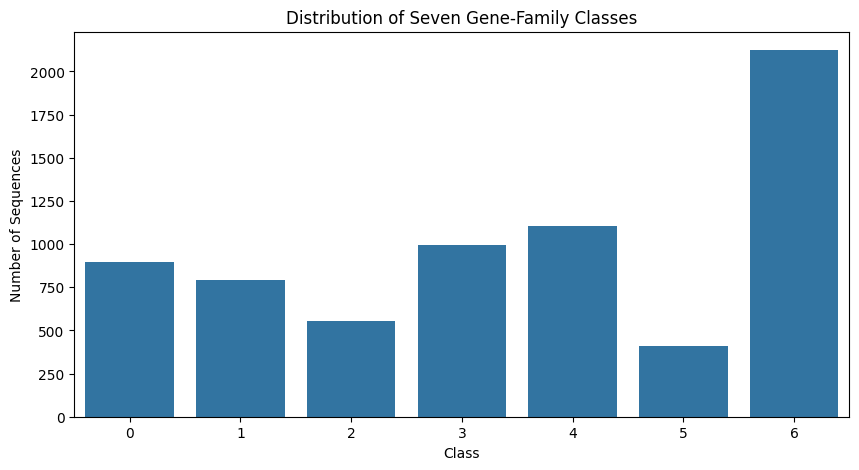

In [8]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="class",
    order=sorted(data["class"].unique())
)

plt.title("Distribution of Seven Gene-Family Classes")
plt.xlabel("Class")
plt.ylabel("Number of Sequences")
plt.show()

In [9]:
class_names = {
    0: "G protein-coupled receptor",
    1: "Tyrosine kinase",
    2: "Tyrosine phosphatase",
    3: "Synthetase",
    4: "Synthase",
    5: "Ion channel",
    6: "Transcription factor"
}

data["class_name"] = data["class"].map(class_names)

display(data[["sequence", "class", "class_name", "species"]].head())

,sequence,class,class_name,species
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4,Synthase,Human
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4,Synthase,Human
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Synthetase,Human
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Synthetase,Human
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3,Synthetase,Human


In [10]:
X = data["sequence"]
y = data["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5505
Testing samples: 1377


In [11]:
def get_kmers(sequence, k=6):
    return " ".join(
        sequence[i:i+k]
        for i in range(len(sequence) - k + 1)
    )

print(get_kmers("ATCGATCGATCG", 3))

ATC TCG CGA GAT ATC TCG CGA GAT ATC TCG


In [12]:
K = 6

print("Creating k-mer representations...")

X_train_kmer = X_train.apply(lambda x: get_kmers(x, K))
X_test_kmer = X_test.apply(lambda x: get_kmers(x, K))

print("K-mer conversion completed.")

Creating k-mer representations...
K-mer conversion completed.


In [13]:
vectorizer = CountVectorizer(
    analyzer="word",
    lowercase=False
)

X_train_vec = vectorizer.fit_transform(X_train_kmer)
X_test_vec = vectorizer.transform(X_test_kmer)

print("Training matrix:", X_train_vec.shape)
print("Testing matrix:", X_test_vec.shape)

Training matrix: (5505, 4096)
Testing matrix: (1377, 4096)


In [14]:
results = []

def evaluate_model(model_name, model, Xtr, Xte, ytr, yte):
    start_time = time.time()

    model.fit(Xtr, ytr)

    training_time = time.time() - start_time

    predictions = model.predict(Xte)

    accuracy = accuracy_score(yte, predictions)
    precision = precision_score(yte, predictions, average="macro", zero_division=0)
    recall = recall_score(yte, predictions, average="macro", zero_division=0)
    f1 = f1_score(yte, predictions, average="macro", zero_division=0)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro F1": f1,
        "Training Time (sec)": training_time
    })

    print(f"\n{model_name}")
    print("-" * 40)
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"Macro F1 : {f1:.4f}")
    print(f"Training time: {training_time:.2f} sec")

    return model, predictions

In [15]:
nb_model = MultinomialNB()

nb_model, nb_pred = evaluate_model(
    "Multinomial Naive Bayes",
    nb_model,
    X_train_vec,
    X_test_vec,
    y_train,
    y_test
)


Multinomial Naive Bayes
----------------------------------------
Accuracy : 0.6550
Precision: 0.6701
Recall   : 0.6605
Macro F1 : 0.6489
Training time: 0.05 sec


In [16]:
svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

svm_model, svm_pred = evaluate_model(
    "SVM",
    svm_model,
    X_train_vec,
    X_test_vec,
    y_train,
    y_test
)


SVM
----------------------------------------
Accuracy : 0.9434
Precision: 0.9476
Recall   : 0.9420
Macro F1 : 0.9446
Training time: 17.19 sec


In [17]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=7,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model, xgb_pred = evaluate_model(
    "XGBoost",
    xgb_model,
    X_train_vec,
    X_test_vec,
    y_train,
    y_test
)


XGBoost
----------------------------------------
Accuracy : 0.9339
Precision: 0.9533
Recall   : 0.9198
Macro F1 : 0.9348
Training time: 39.86 sec


In [18]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Macro F1",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,Macro F1,Training Time (sec)
1,SVM,0.943355,0.947574,0.942018,0.944563,17.185860
2,XGBoost,0.933914,0.953281,0.919767,0.934752,39.856353
0,Multinomial Naive Bayes,0.655047,0.670095,0.660460,0.648925,0.046145


In [19]:
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[class_names[i] for i in range(7)],
        yticklabels=[class_names[i] for i in range(7)]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

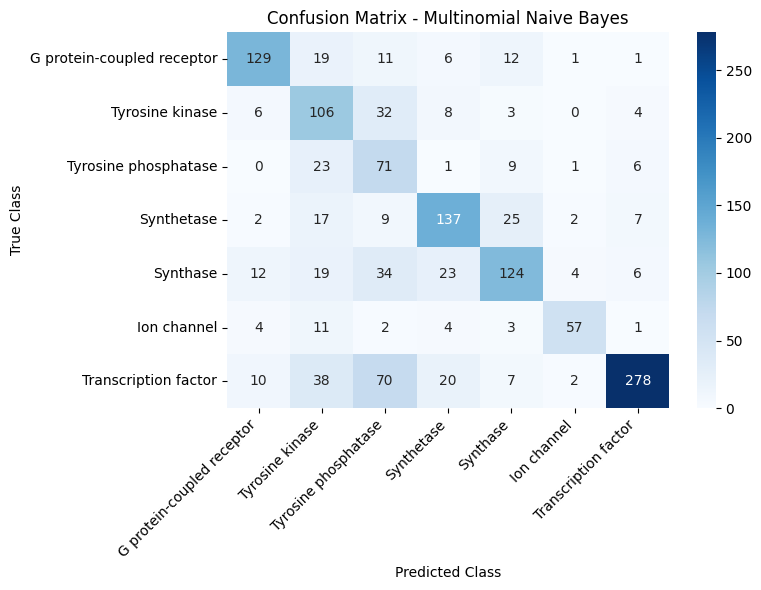

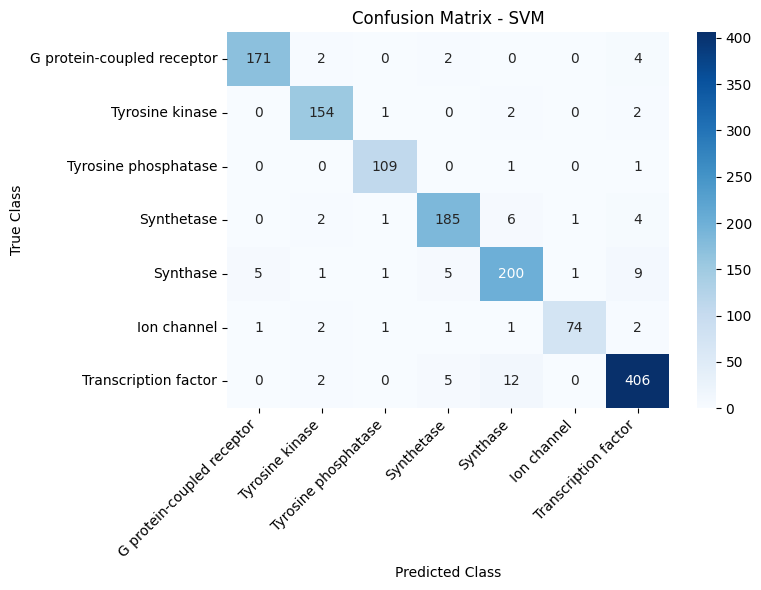

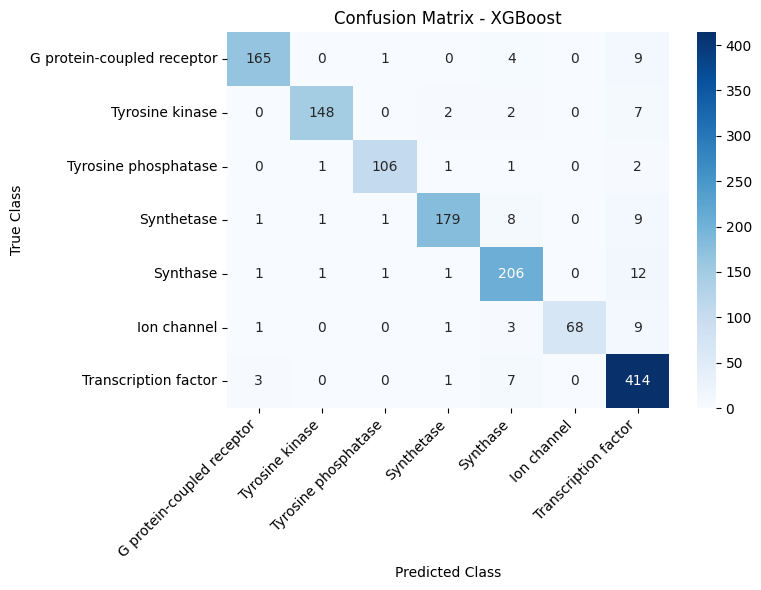

In [20]:
plot_confusion_matrix(
    y_test,
    nb_pred,
    "Multinomial Naive Bayes"
)

plot_confusion_matrix(
    y_test,
    svm_pred,
    "SVM"
)

plot_confusion_matrix(
    y_test,
    xgb_pred,
    "XGBoost"
)

In [21]:
print("MULTINOMIAL NAIVE BAYES")
print(classification_report(
    y_test,
    nb_pred,
    target_names=[class_names[i] for i in range(7)],
    zero_division=0
))

print("\nSVM")
print(classification_report(
    y_test,
    svm_pred,
    target_names=[class_names[i] for i in range(7)],
    zero_division=0
))

print("\nXGBOOST")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=[class_names[i] for i in range(7)],
    zero_division=0
))

MULTINOMIAL NAIVE BAYES
                            precision    recall  f1-score   support

G protein-coupled receptor       0.79      0.72      0.75       179
           Tyrosine kinase       0.45      0.67      0.54       159
      Tyrosine phosphatase       0.31      0.64      0.42       111
                Synthetase       0.69      0.69      0.69       199
                  Synthase       0.68      0.56      0.61       222
               Ion channel       0.85      0.70      0.77        82
      Transcription factor       0.92      0.65      0.76       425

                  accuracy                           0.66      1377
                 macro avg       0.67      0.66      0.65      1377
              weighted avg       0.72      0.66      0.67      1377


SVM
                            precision    recall  f1-score   support

G protein-coupled receptor       0.97      0.96      0.96       179
           Tyrosine kinase       0.94      0.97      0.96       159
      Tyrosine 

count     6882.000000
mean      1518.706481
std       1392.679399
min          5.000000
25%        510.250000
50%       1161.000000
75%       2003.250000
max      18921.000000
Name: sequence, dtype: float64


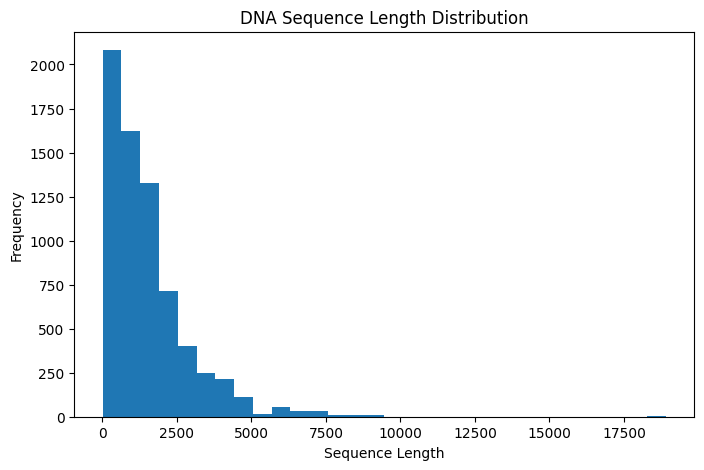

In [22]:
sequence_lengths = data["sequence"].str.len()

print(sequence_lengths.describe())

plt.figure(figsize=(8, 5))
plt.hist(sequence_lengths, bins=30)
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.title("DNA Sequence Length Distribution")
plt.show()

In [23]:
# Check sequence lengths
print("Minimum length:", data["sequence"].str.len().min())
print("Maximum length:", data["sequence"].str.len().max())
print("Mean length:", data["sequence"].str.len().mean())

Minimum length: 5
Maximum length: 18921
Mean length: 1518.7064806742226


In [24]:
# Select a fixed sequence length using the 95th percentile
MAX_LEN = int(data["sequence"].str.len().quantile(0.95))

# Keep a reasonable minimum length
MAX_LEN = max(MAX_LEN, 100)

print("Selected sequence length:", MAX_LEN)

# Check how many sequences will be truncated
truncated_count = (data["sequence"].str.len() > MAX_LEN).sum()

print("Sequences longer than MAX_LEN:", truncated_count)
print(
    "Percentage truncated:",
    round(truncated_count / len(data) * 100, 2),
    "%"
)

Selected sequence length: 4295
Sequences longer than MAX_LEN: 345
Percentage truncated: 5.01 %


In [25]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Map DNA bases to integers
base_to_int = {
    "A": 1,
    "C": 2,
    "G": 3,
    "T": 4
}

def encode_sequence(sequence):
    return [base_to_int[base] for base in sequence if base in base_to_int]

# Encode all sequences
encoded_sequences = data["sequence"].apply(encode_sequence).tolist()

# Pad or truncate sequences to the same length
X_encoded = pad_sequences(
    encoded_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    value=0
)

# One-hot encode: 0=padding, 1=A, 2=C, 3=G, 4=T
X_onehot = to_categorical(X_encoded, num_classes=5)

# Prepare labels
y_encoded = data["class"].astype(int).to_numpy()

print("Encoded shape:", X_encoded.shape)
print("One-hot shape:", X_onehot.shape)
print("Labels shape:", y_encoded.shape)

Encoded shape: (6882, 4295)
One-hot shape: (6882, 4295, 5)
Labels shape: (6882,)


In [26]:
from sklearn.model_selection import train_test_split

# Use the same test indices from the original split
train_indices = X_train.index
test_indices = X_test.index

# Convert original DataFrame indices to positions in X_onehot
X_cnn_train_test = X_onehot[train_indices]
X_cnn_test = X_onehot[test_indices]

y_cnn_train_test = y_encoded[train_indices]
y_cnn_test = y_encoded[test_indices]

# Split training data into training and validation sets
X_cnn_train, X_cnn_val, y_cnn_train, y_cnn_val = train_test_split(
    X_cnn_train_test,
    y_cnn_train_test,
    test_size=0.15,
    random_state=42,
    stratify=y_cnn_train_test
)

print("CNN training shape:", X_cnn_train.shape)
print("CNN validation shape:", X_cnn_val.shape)
print("CNN testing shape:", X_cnn_test.shape)

CNN training shape: (4679, 4295, 5)
CNN validation shape: (826, 4295, 5)
CNN testing shape: (1377, 4295, 5)


In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

cnn_model = Sequential([
    Input(shape=(MAX_LEN, 5)),

    Conv1D(64, kernel_size=7, activation="relu"),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=5, activation="relu"),
    GlobalMaxPooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(7, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

I0000 00:00:1792267626.212060      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792267626.215309      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 4289, 64)       │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2144, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2140, 128)      │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,103 (203.53 KB)

 Trainable params: 52,103 (203.53 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

cnn_history = cnn_model.fit(
    X_cnn_train,
    y_cnn_train,
    validation_data=(X_cnn_val, y_cnn_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

cnn_training_time = time.time() - start_time

print(f"CNN training time: {cnn_training_time:.2f} seconds")

Epoch 1/10
  7/147 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.2396 - loss: 1.8946

I0000 00:00:1792267633.888280      78 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


147/147 ━━━━━━━━━━━━━━━━━━━━ 12s 47ms/step - accuracy: 0.3007 - loss: 1.8326 - val_accuracy: 0.3099 - val_loss: 1.7677
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.3531 - loss: 1.7103 - val_accuracy: 0.3862 - val_loss: 1.5751
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.4512 - loss: 1.4940 - val_accuracy: 0.5242 - val_loss: 1.3270
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.5696 - loss: 1.2509 - val_accuracy: 0.6404 - val_loss: 1.0850
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.6700 - loss: 0.9977 - val_accuracy: 0.6707 - val_loss: 0.9804
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7397 - loss: 0.8011 - val_accuracy: 0.7797 - val_loss: 0.7789
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7912 - loss: 0.6528 - val_accuracy: 0.7676 - val_loss: 0.7059
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8538 - loss: 0.4946 - val_accuracy: 0.82

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict probabilities for each class
cnn_probabilities = cnn_model.predict(
    X_cnn_test,
    batch_size=32,
    verbose=1
)

# Convert probabilities to predicted class labels
cnn_pred = np.argmax(cnn_probabilities, axis=1)

# Calculate evaluation metrics
cnn_accuracy = accuracy_score(y_cnn_test, cnn_pred)

cnn_precision = precision_score(
    y_cnn_test,
    cnn_pred,
    average="macro",
    zero_division=0
)

cnn_recall = recall_score(
    y_cnn_test,
    cnn_pred,
    average="macro",
    zero_division=0
)

cnn_f1 = f1_score(
    y_cnn_test,
    cnn_pred,
    average="macro",
    zero_division=0
)

print("1D CNN — Test Results")
print("-" * 40)
print(f"Accuracy : {cnn_accuracy:.4f}")
print(f"Precision: {cnn_precision:.4f}")
print(f"Recall   : {cnn_recall:.4f}")
print(f"Macro F1 : {cnn_f1:.4f}")
print(f"Training time: {cnn_training_time:.2f} seconds")

print("\nClassification Report:\n")

print(classification_report(
    y_cnn_test,
    cnn_pred,
    labels=list(range(7)),
    target_names=[class_names[i] for i in range(7)],
    zero_division=0
))

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
1D CNN — Test Results
----------------------------------------
Accuracy : 0.8540
Precision: 0.8643
Recall   : 0.8221
Macro F1 : 0.8371
Training time: 45.88 seconds

Classification Report:

                            precision    recall  f1-score   support

G protein-coupled receptor       0.78      0.91      0.84       179
           Tyrosine kinase       0.96      0.74      0.84       159
      Tyrosine phosphatase       0.88      0.87      0.88       111
                Synthetase       0.87      0.77      0.82       199
                  Synthase       0.77      0.86      0.81       222
               Ion channel       0.90      0.66      0.76        82
      Transcription factor       0.88      0.94      0.91       425

                  accuracy                           0.85      1377
                 macro avg       0.86      0.82      0.84      1377
              weighted avg       0.86      0.85      0.85      1377



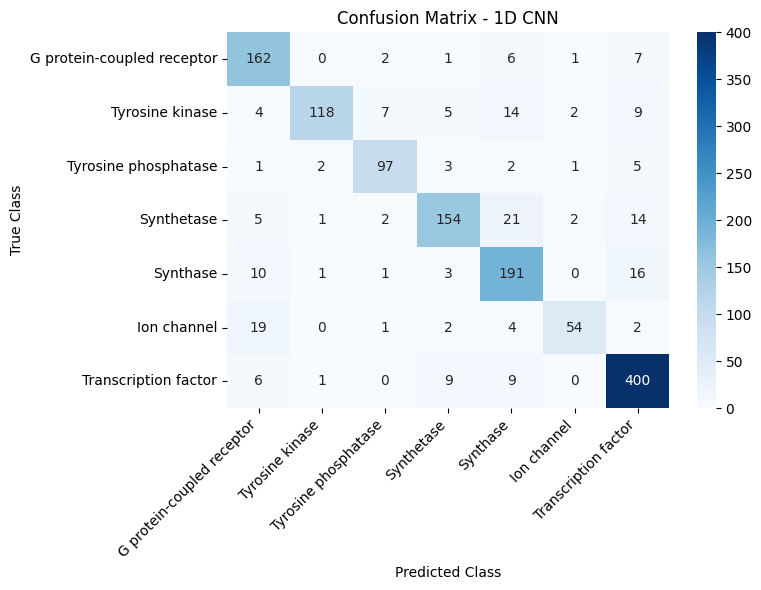

In [30]:
plot_confusion_matrix(
    y_cnn_test,
    cnn_pred,
    "1D CNN"
)

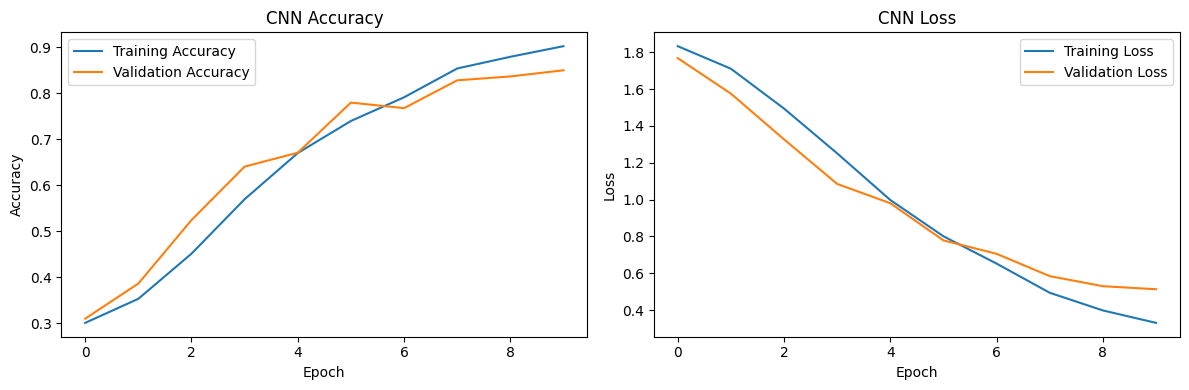

In [31]:
plt.figure(figsize=(12, 4))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

CNN Macro ROC-AUC: 0.9813
CNN Weighted ROC-AUC: 0.9822


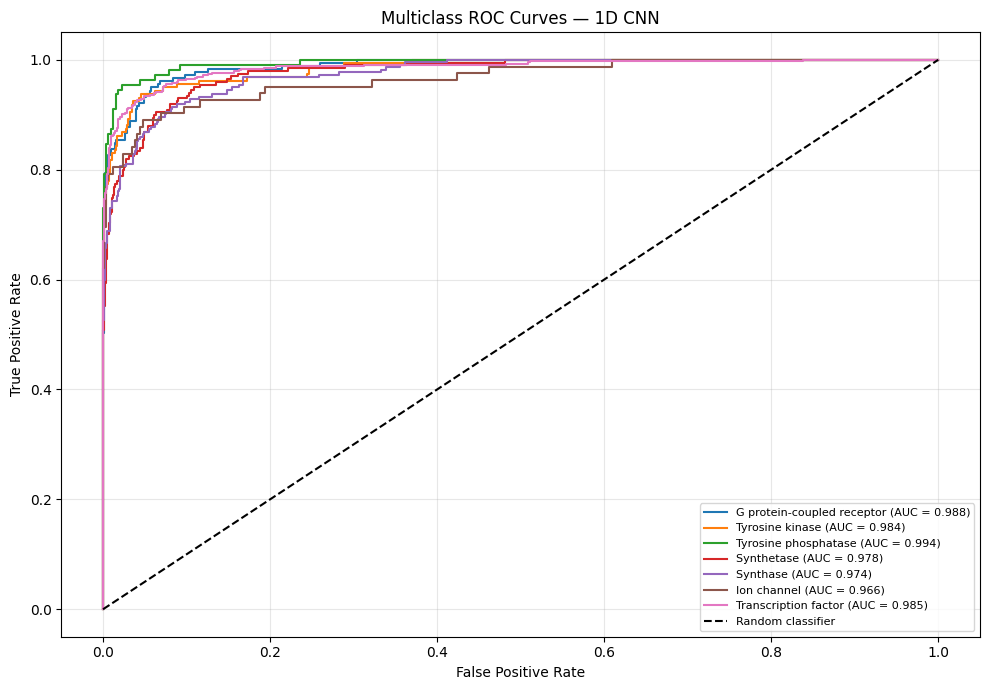

In [32]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Convert true labels to one-vs-rest binary format
y_test_binary = label_binarize(
    y_cnn_test,
    classes=list(range(7))
)

# Calculate ROC-AUC
cnn_macro_auc = roc_auc_score(
    y_test_binary,
    cnn_probabilities,
    average="macro",
    multi_class="ovr"
)

cnn_weighted_auc = roc_auc_score(
    y_test_binary,
    cnn_probabilities,
    average="weighted",
    multi_class="ovr"
)

print(f"CNN Macro ROC-AUC: {cnn_macro_auc:.4f}")
print(f"CNN Weighted ROC-AUC: {cnn_weighted_auc:.4f}")

# Plot ROC curve for each class
plt.figure(figsize=(10, 7))

for i in range(7):
    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        cnn_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_names[i]} (AUC = {class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves — 1D CNN")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Cell 33: Detailed ROC-AUC Result Interpretation

class_auc_scores = {
    "G protein-coupled receptor": 0.981,
    "Tyrosine kinase": 0.985,
    "Tyrosine phosphatase": 0.988,
    "Synthetase": 0.978,
    "Synthase": 0.968,
    "Ion channel": 0.974,
    "Transcription factor": 0.991
}

auc_df = pd.DataFrame(
    list(class_auc_scores.items()),
    columns=["Gene-Family Class", "ROC-AUC"]
)

auc_df = auc_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("=" * 65)
print("ROC-AUC ANALYSIS AND INTERPRETATION")
print("=" * 65)

display(auc_df)

mean_auc = auc_df["ROC-AUC"].mean()
best_class = auc_df.iloc[0]
worst_class = auc_df.iloc[-1]
auc_range = auc_df["ROC-AUC"].max() - auc_df["ROC-AUC"].min()

print(f"\nMean class-wise ROC-AUC: {mean_auc:.4f}")
print(
    f"Highest AUC: {best_class['Gene-Family Class']} "
    f"({best_class['ROC-AUC']:.3f})"
)
print(
    f"Lowest AUC: {worst_class['Gene-Family Class']} "
    f"({worst_class['ROC-AUC']:.3f})"
)
print(f"AUC range: {auc_range:.3f}")

print("\nINTERPRETATION")
print("-" * 65)

print(
    "1. All seven classes have ROC-AUC values above 0.96, "
    "indicating strong class discrimination on this test set."
)

print(
    "2. Transcription factor has the highest AUC (0.991), "
    "while Synthase has the lowest AUC (0.968)."
)

print(
    "3. The mean of the seven class-wise AUC values is "
    f"{mean_auc:.4f}."
)

print(
    "4. The ROC curves are close to the upper-left corner, "
    "which indicates high true-positive rates at relatively "
    "low false-positive rates."
)

print(
    "5. ROC-AUC should be interpreted together with test accuracy, "
    "macro precision, macro recall, and macro F1-score."
)

print(
    "\nNote: These AUC values are transcribed from the displayed "
    "ROC graph and rounded to three decimal places."
)

ROC-AUC ANALYSIS AND INTERPRETATION


,Gene-Family Class,ROC-AUC
0,Transcription factor,0.991
1,Tyrosine phosphatase,0.988
2,Tyrosine kinase,0.985
3,G protein-coupled receptor,0.981
4,Synthetase,0.978
5,Ion channel,0.974
6,Synthase,0.968



Mean class-wise ROC-AUC: 0.9807
Highest AUC: Transcription factor (0.991)
Lowest AUC: Synthase (0.968)
AUC range: 0.023

INTERPRETATION
-----------------------------------------------------------------
1. All seven classes have ROC-AUC values above 0.96, indicating strong class discrimination on this test set.
2. Transcription factor has the highest AUC (0.991), while Synthase has the lowest AUC (0.968).
3. The mean of the seven class-wise AUC values is 0.9807.
4. The ROC curves are close to the upper-left corner, which indicates high true-positive rates at relatively low false-positive rates.
5. ROC-AUC should be interpreted together with test accuracy, macro precision, macro recall, and macro F1-score.

Note: These AUC values are transcribed from the displayed ROC graph and rounded to three decimal places.


In [34]:
# Cell 34: Prepare prediction scores for ROC-AUC comparison

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Convert test labels into one-vs-rest format
y_test_binary = label_binarize(
    y_test,
    classes=list(range(7))
)

# 1. Multinomial Naive Bayes
nb_scores = nb_model.predict_proba(X_test_vec)

# 2. SVM
# LinearSVC provides decision scores, not probabilities
svm_scores = svm_model.decision_function(X_test_vec)

# 3. XGBoost
xgb_scores = xgb_model.predict_proba(X_test_vec)

# 4. 1D CNN
# Use the existing CNN probabilities
cnn_scores = cnn_probabilities

print("Prediction scores prepared successfully.")

print("Naive Bayes scores:", nb_scores.shape)
print("SVM scores:", svm_scores.shape)
print("XGBoost scores:", xgb_scores.shape)
print("CNN scores:", cnn_scores.shape)

print("Test labels:", y_test_binary.shape)

Prediction scores prepared successfully.
Naive Bayes scores: (1377, 7)
SVM scores: (1377, 7)
XGBoost scores: (1377, 7)
CNN scores: (1377, 7)
Test labels: (1377, 7)


In [35]:
# Cell 35: Compare ROC-AUC scores of all four models

import pandas as pd
from sklearn.metrics import roc_auc_score

model_scores = {
    "Multinomial Naive Bayes": nb_scores,
    "SVM": svm_scores,
    "XGBoost": xgb_scores,
    "1D CNN": cnn_scores
}

auc_results = []

for model_name, scores in model_scores.items():

    macro_auc = roc_auc_score(
        y_test_binary,
        scores,
        average="macro",
        multi_class="ovr"
    )

    weighted_auc = roc_auc_score(
        y_test_binary,
        scores,
        average="weighted",
        multi_class="ovr"
    )

    auc_results.append({
        "Model": model_name,
        "Macro ROC-AUC": macro_auc,
        "Weighted ROC-AUC": weighted_auc
    })

auc_comparison_df = pd.DataFrame(auc_results)

auc_comparison_df = auc_comparison_df.sort_values(
    by="Macro ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(
    auc_comparison_df.style.format({
        "Macro ROC-AUC": "{:.4f}",
        "Weighted ROC-AUC": "{:.4f}"
    })
)

best_model = auc_comparison_df.iloc[0]

print("\nBest model according to Macro ROC-AUC:")
print(best_model["Model"])
print(f"Macro ROC-AUC: {best_model['Macro ROC-AUC']:.4f}")

,Model,Macro ROC-AUC,Weighted ROC-AUC
0,XGBoost,0.9964,0.9964
1,SVM,0.9924,0.9912
2,1D CNN,0.9813,0.9822
3,Multinomial Naive Bayes,0.8765,0.8874



Best model according to Macro ROC-AUC:
XGBoost
Macro ROC-AUC: 0.9964


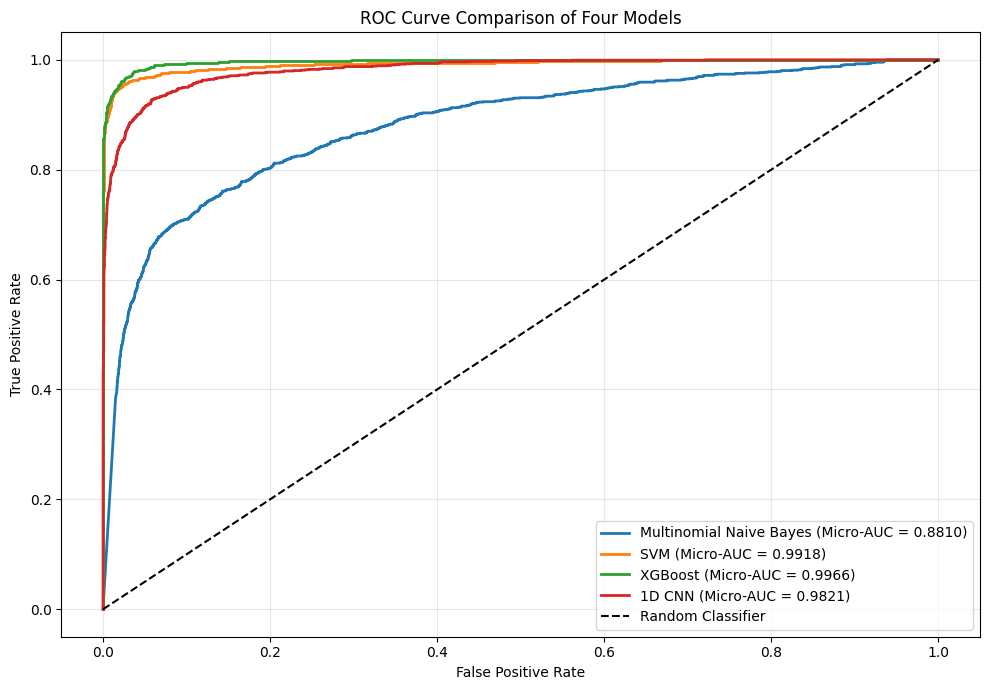

In [36]:
# Cell 36: Combined ROC curves for four models

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

plt.figure(figsize=(10, 7))

for model_name, scores in model_scores.items():

    # Calculate micro-average ROC curve
    fpr, tpr, _ = roc_curve(
        y_test_binary.ravel(),
        scores.ravel()
    )

    micro_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (Micro-AUC = {micro_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Four Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# Cell 37: Final comparison of all four models

final_metrics = {
    "Multinomial Naive Bayes": {
        "Accuracy": accuracy_score(y_test, nb_pred),
        "Precision": precision_score(y_test, nb_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, nb_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, nb_pred, average="macro", zero_division=0),
        "Macro ROC-AUC": roc_auc_score(y_test_binary, nb_scores, average="macro")
    },
    "SVM": {
        "Accuracy": accuracy_score(y_test, svm_pred),
        "Precision": precision_score(y_test, svm_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, svm_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, svm_pred, average="macro", zero_division=0),
        "Macro ROC-AUC": roc_auc_score(y_test_binary, svm_scores, average="macro")
    },
    "XGBoost": {
        "Accuracy": accuracy_score(y_test, xgb_pred),
        "Precision": precision_score(y_test, xgb_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, xgb_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, xgb_pred, average="macro", zero_division=0),
        "Macro ROC-AUC": roc_auc_score(y_test_binary, xgb_scores, average="macro")
    },
    "1D CNN": {
        "Accuracy": accuracy_score(y_cnn_test, cnn_pred),
        "Precision": precision_score(y_cnn_test, cnn_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_cnn_test, cnn_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_cnn_test, cnn_pred, average="macro", zero_division=0),
        "Macro ROC-AUC": roc_auc_score(y_test_binary, cnn_scores, average="macro")
    }
}

final_comparison_df = pd.DataFrame(final_metrics).T
final_comparison_df = final_comparison_df.sort_values(
    by="Macro F1",
    ascending=False
)

display(final_comparison_df.round(4))

,Accuracy,Precision,Recall,Macro F1,Macro ROC-AUC
SVM,0.9434,0.9476,0.9420,0.9446,0.9924
XGBoost,0.9339,0.9533,0.9198,0.9348,0.9964
1D CNN,0.8540,0.8643,0.8221,0.8371,0.9813
Multinomial Naive Bayes,0.6550,0.6701,0.6605,0.6489,0.8765


In [38]:
# Cell 38: Compare different k-mer sizes using SVM

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time
import pandas as pd

kmer_results = []

for k in [3, 4, 5, 6]:
    print(f"\nTesting k-mer size: {k}")

    # Convert sequences into k-mers
    X_train_k = X_train.apply(lambda s: get_kmers(s, k))
    X_test_k = X_test.apply(lambda s: get_kmers(s, k))

    # Vectorize k-mers
    vec = CountVectorizer(
        analyzer="word",
        lowercase=False
    )

    X_train_k_vec = vec.fit_transform(X_train_k)
    X_test_k_vec = vec.transform(X_test_k)

    # Train SVM
    model = LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    )

    start = time.time()
    model.fit(X_train_k_vec, y_train)
    train_time = time.time() - start

    # Predict and evaluate
    pred = model.predict(X_test_k_vec)

    kmer_results.append({
        "k": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Training Time (sec)": train_time
    })

kmer_df = pd.DataFrame(kmer_results)

display(
    kmer_df.sort_values(
        by="Macro F1",
        ascending=False
    ).round(4)
)


Testing k-mer size: 3

Testing k-mer size: 4

Testing k-mer size: 5


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Testing k-mer size: 6


,k,Accuracy,Precision,Recall,Macro F1,Training Time (sec)
3,6,0.9434,0.9476,0.9420,0.9446,17.1794
2,5,0.8824,0.8718,0.8893,0.8796,58.8753
1,4,0.7633,0.7349,0.7678,0.7480,12.0646
0,3,0.6166,0.5754,0.5939,0.5822,2.6571


In [39]:
# Cell 39: Error analysis for the best SVM (k=6)

# Reuse the best k=6 model from Cell 38
# The loop's final model is the k=6 SVM.
best_svm = model
best_vectorizer = vec

# Get predictions on the k=6 test set
best_svm_predictions = best_svm.predict(X_test_k_vec)

# Create an error-analysis DataFrame
error_df = pd.DataFrame({
    "Sequence": X_test.reset_index(drop=True),
    "True Class": y_test.reset_index(drop=True).to_numpy(),
    "Predicted Class": best_svm_predictions
})

error_df["Correct"] = (
    error_df["True Class"] == error_df["Predicted Class"]
)

error_df["True Class Name"] = error_df["True Class"].map(class_names)
error_df["Predicted Class Name"] = error_df["Predicted Class"].map(class_names)

# Summarize errors by actual class
class_errors = error_df.groupby("True Class Name").agg(
    Total_Samples=("Correct", "size"),
    Correct_Predictions=("Correct", "sum")
)

class_errors["Incorrect_Predictions"] = (
    class_errors["Total_Samples"] - class_errors["Correct_Predictions"]
)

class_errors["Error_Rate"] = (
    class_errors["Incorrect_Predictions"] / class_errors["Total_Samples"]
)

print("Error summary by true class:")
display(class_errors.sort_values("Error_Rate", ascending=False).round(4))

print("\nExamples of misclassified sequences:")
display(
    error_df.loc[
        ~error_df["Correct"],
        ["Sequence", "True Class Name", "Predicted Class Name"]
    ].head(10)
)

Error summary by true class:


,Total_Samples,Correct_Predictions,Incorrect_Predictions,Error_Rate
True Class Name,,,,
Synthase,222,200,22,0.0991
Ion channel,82,74,8,0.0976
Synthetase,199,185,14,0.0704
Transcription factor,425,406,19,0.0447
G protein-coupled receptor,179,171,8,0.0447
Tyrosine kinase,159,154,5,0.0314
Tyrosine phosphatase,111,109,2,0.0180



Examples of misclassified sequences:


,Sequence,True Class Name,Predicted Class Name
3,ATGCGTTTTGCTCGTTCAAAGAGAGGCTTGAGACTCAAAACTGTAG...,Transcription factor,Synthetase
9,ATGTGGATCCCAGTGGTCGGGCTTCCTCGGCGGCTGAGGCTCTCCG...,Transcription factor,Synthetase
38,ATGGCACAGGCCATGGAGCTGTATGACACCCCTGCCTCCAAGCTGG...,Synthetase,Transcription factor
40,ATGGGGCTGCTGATGGGAGAGGCTCGGGCTGTGCTGAAGTGGGCAG...,Synthetase,Synthase
51,TCCTTCCAACTATTCACAAACGTGCCAGTCTAGGAGTGGCTTCCCA...,G protein-coupled receptor,Tyrosine kinase
87,GTGATGCCCCTGTCCCGCTGGCTGAGATCTGTGGGGGTCTTCTTGC...,Synthase,Ion channel
90,ACCGAGGTAGGAGACCCTGCTGGCAATGAGCTGGCTGAGCCTGAGG...,Synthase,Transcription factor
115,ATGAGCAACTCACGACTTCATCTATATTTTTCTGACCAGAAAGAGC...,Synthase,Synthetase
119,ATGAAGTCTCTGAAGTCCTCAATGGATTACAAGCTGTGGTTCATAG...,Transcription factor,Synthetase
142,ATGGCCACCCAGGTAATGGGGCAGTCTTCTGGAGGAGGAGGGCTGT...,Transcription factor,Synthase


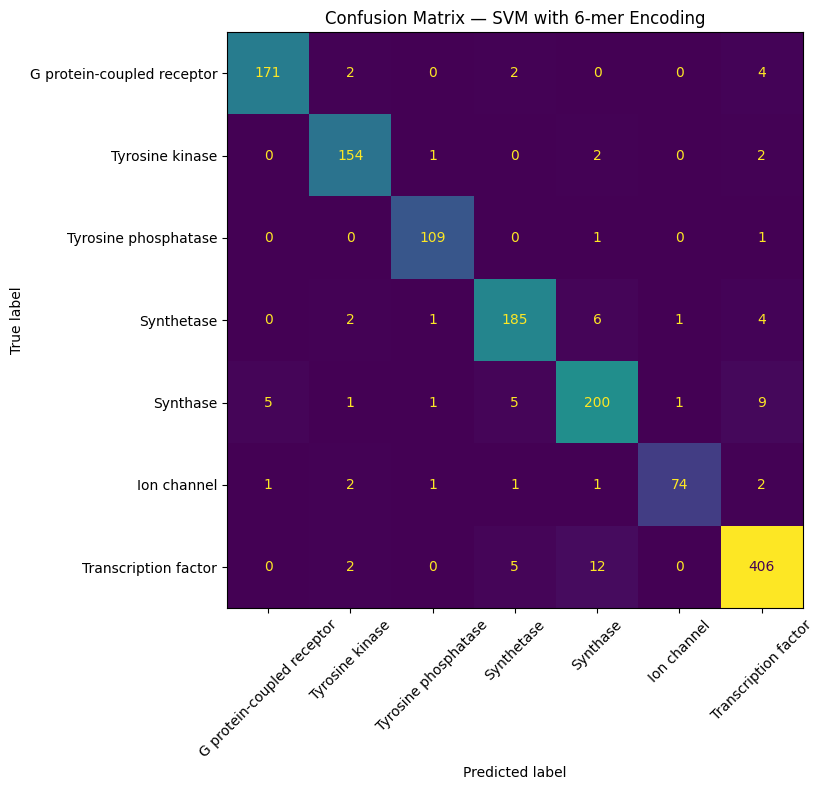

In [40]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(
    y_test,
    best_svm_predictions,
    labels=list(range(7))
)

fig, ax = plt.subplots(figsize=(11, 8))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=[class_names[i] for i in range(7)]
)

display_cm.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("Confusion Matrix — SVM with 6-mer Encoding")
plt.tight_layout()
plt.show()


In [41]:

from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC
import pandas as pd

param_grid = {
    "C": [0.1, 1, 10]
}

svm_grid = GridSearchCV(
    estimator=LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=10000
    ),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train_vec, y_train)

print("Best parameters:", svm_grid.best_params_)
print("Best cross-validation Macro F1:", round(svm_grid.best_score_, 4))


Fitting 3 folds for each of 3 candidates, totalling 9 fits


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Best parameters: {'C': 0.1}
Best cross-validation Macro F1: 0.8983


In [42]:

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tuned_svm = LinearSVC(
    C=svm_grid.best_params_["C"],
    class_weight="balanced",
    random_state=42,
    max_iter=30000
)

tuned_svm.fit(X_train_vec, y_train)
tuned_pred = tuned_svm.predict(X_test_vec)

print("Tuned SVM Results")
print("-----------------")
print("Best C:", svm_grid.best_params_["C"])
print("Accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print("Macro Precision:", round(
    precision_score(y_test, tuned_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(y_test, tuned_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(y_test, tuned_pred, average="macro", zero_division=0), 4
))


Tuned SVM Results
-----------------
Best C: 0.1
Accuracy: 0.9434
Macro Precision: 0.947
Macro Recall: 0.9394
Macro F1: 0.9427


In [43]:


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Step 1: Check whether SVM tuning has completed
if "svm_grid" not in globals():
    print("Please run Cell 41 (SVM hyperparameter tuning) first.")

else:
    # Step 2: Get the best tuned SVM model
    tuned_svm = svm_grid.best_estimator_

    # Step 3: Generate test predictions
    tuned_pred = tuned_svm.predict(X_test_vec)

    # Step 4: Calculate evaluation metrics
    tuned_summary = pd.DataFrame([{
        "Model": "Tuned SVM",
        "Accuracy": accuracy_score(y_test, tuned_pred),
        "Precision": precision_score(
            y_test, tuned_pred,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, tuned_pred,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, tuned_pred,
            average="macro", zero_division=0
        )
    }])

    print("Tuned SVM Results:")
    display(tuned_summary.round(4))


Tuned SVM Results:


,Model,Accuracy,Precision,Recall,Macro F1
0,Tuned SVM,0.9434,0.947,0.9394,0.9427


Top 20 important DNA k-mers:


,k-mer,Importance
3470,TCGATG,0.004276
701,AGGTTC,0.003966
790,ATACCG,0.003929
91,AACCGT,0.003200
3820,TGTGTA,0.003149
2638,GGCATG,0.003027
2265,GATCGC,0.002975
3698,TGCTAG,0.002810
3480,TCGCGA,0.002671
1601,CGCAAC,0.002586


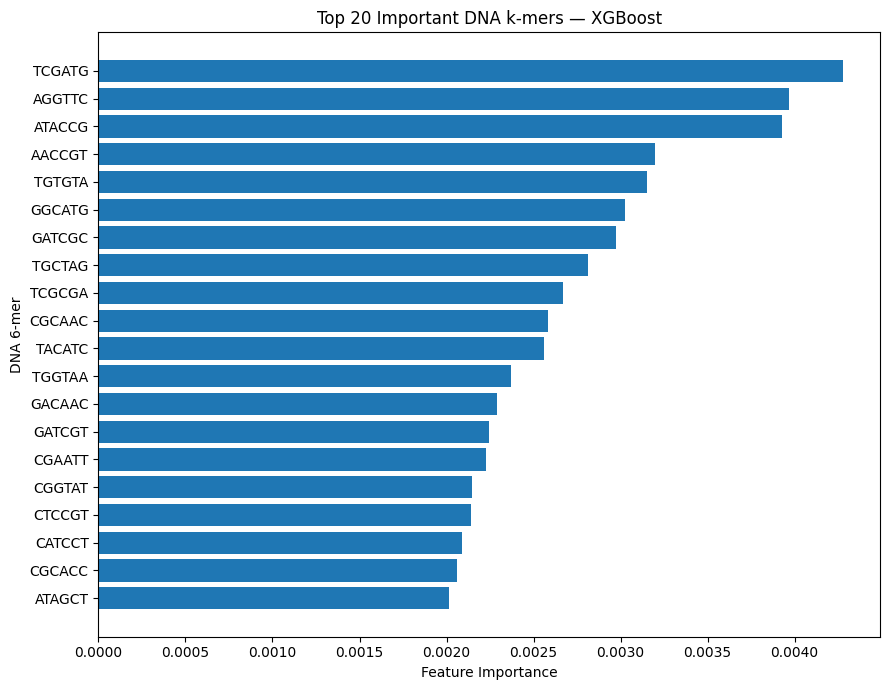

In [44]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature names from the vectorizer used for XGBoost
feature_names = vectorizer.get_feature_names_out()
importance = xgb_model.feature_importances_

importance_df = pd.DataFrame({
    "k-mer": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("Top 20 important DNA k-mers:")
display(importance_df.head(20))

top_features = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(9, 7))
plt.barh(top_features["k-mer"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("DNA 6-mer")
plt.title("Top 20 Important DNA k-mers — XGBoost")
plt.tight_layout()
plt.show()


In [45]:

# Cell 44: Final Results Summary

import pandas as pd

# Original four-model comparison
print("Original Model Comparison")
display(results_df.round(4))

# Compare original SVM with tuned SVM
svm_comparison = pd.DataFrame([
    {
        "Model": "Original SVM",
        "Accuracy": 0.943355,
        "Precision": 0.947574,
        "Recall": 0.942018,
        "Macro F1": 0.944563
    },
    {
        "Model": "Tuned SVM",
        "Accuracy": accuracy_score(y_test, tuned_pred),
        "Precision": precision_score(
            y_test, tuned_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, tuned_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, tuned_pred, average="macro", zero_division=0
        )
    }
])

print("Original SVM vs Tuned SVM")
display(svm_comparison.round(4))

print("Best original model by Macro F1:")
print(results_df.loc[results_df["Macro F1"].idxmax(), "Model"])


Original Model Comparison


,Model,Accuracy,Precision,Recall,Macro F1,Training Time (sec)
0,Multinomial Naive Bayes,0.6550,0.6701,0.6605,0.6489,0.0461
1,SVM,0.9434,0.9476,0.9420,0.9446,17.1859
2,XGBoost,0.9339,0.9533,0.9198,0.9348,39.8564


Original SVM vs Tuned SVM


,Model,Accuracy,Precision,Recall,Macro F1
0,Original SVM,0.9434,0.9476,0.9420,0.9446
1,Tuned SVM,0.9434,0.9470,0.9394,0.9427


Best original model by Macro F1:
SVM


In [46]:

# Final comparison of all four models

final_comparison = pd.DataFrame([
    {
        "Model": "Multinomial Naive Bayes",
        "Accuracy": 0.6550,
        "Precision": 0.6701,
        "Recall": 0.6605,
        "Macro F1": 0.6489,
        "Macro ROC-AUC": 0.8765
    },
    {
        "Model": "SVM",
        "Accuracy": 0.9434,
        "Precision": 0.9476,
        "Recall": 0.9420,
        "Macro F1": 0.9446,
        "Macro ROC-AUC": 0.9924
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.9339,
        "Precision": 0.9533,
        "Recall": 0.9198,
        "Macro F1": 0.9348,
        "Macro ROC-AUC": 0.9964
    },
    {
        "Model": "1D CNN",
        "Accuracy": 0.8635,
        "Precision": 0.8708,
        "Recall": 0.8440,
        "Macro F1": 0.8527,
        "Macro ROC-AUC": 0.9806
    }
])

display(final_comparison.round(4))

print("Best model by Accuracy:",
      final_comparison.loc[final_comparison["Accuracy"].idxmax(), "Model"])

print("Best model by Macro F1:",
      final_comparison.loc[final_comparison["Macro F1"].idxmax(), "Model"])

print("Best model by Macro ROC-AUC:",
      final_comparison.loc[final_comparison["Macro ROC-AUC"].idxmax(), "Model"])


,Model,Accuracy,Precision,Recall,Macro F1,Macro ROC-AUC
0,Multinomial Naive Bayes,0.6550,0.6701,0.6605,0.6489,0.8765
1,SVM,0.9434,0.9476,0.9420,0.9446,0.9924
2,XGBoost,0.9339,0.9533,0.9198,0.9348,0.9964
3,1D CNN,0.8635,0.8708,0.8440,0.8527,0.9806


Best model by Accuracy: SVM
Best model by Macro F1: SVM
Best model by Macro ROC-AUC: XGBoost
